## 1. Conventional machine learning

### 1.1. Data loading ridge regression, support vector regression, and Chemprop

In [27]:
from rdkit.Chem import AllChem as chem
from rdkit import Chem as c
import rdkit.DataStructs as data
from rdkit.Chem import Descriptors3D

import os.path as osp
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

import json

data_folder = 'dataset/mossbauer/raw'
smiles_csv = pd.read_csv(osp.join(data_folder, 'annotations.tsv'),sep='\t')

file_list = list(smiles_csv.iloc[:,0])
mol_list = []
density_list = []
quadrupole_list = []

for file in file_list:
    file_path = None
    if(osp.exists((file_path := osp.join(data_folder, file[:-4], 'xtbtopo.mol')))):
        pass
    else:
        file_path = osp.join(data_folder, file[:-4], 'xtbopt.mol')

    desc_path = osp.join(data_folder, file[:-4], 'tblite-data.npz')
    post_processing = np.load(desc_path)

    mol = chem.MolFromMolFile(file_path, sanitize=False, removeHs=False)
    
    # Regenerate computed properties like implicit valence and ring information
    mol.UpdatePropertyCache(strict=False)

    # Apply several sanitization rules
    chem.SanitizeMol(mol,c.SanitizeFlags.SANITIZE_FINDRADICALS| \
                         c.SanitizeFlags.SANITIZE_SETAROMATICITY| \
                         c.SanitizeFlags.SANITIZE_SETCONJUGATION| \
                         c.SanitizeFlags.SANITIZE_SETHYBRIDIZATION| \
                         c.SanitizeFlags.SANITIZE_SYMMRINGS,catchErrors=True)

    iron_index = 0
    for i, a in enumerate(mol.GetAtoms()):
        if a.GetAtomicNum() == 26:
            iron_index = i
            break

    density = [post_processing['tblite0_q_A_alpha'][iron_index] + post_processing['tblite0_q_A_beta'][iron_index],
               post_processing['tblite0_p_s_alpha'][iron_index],
               post_processing['tblite0_p_p_alpha'][iron_index],
               post_processing['tblite0_p_d_alpha'][iron_index],
               post_processing['tblite0_p_s_beta'][iron_index],
               post_processing['tblite0_p_p_beta'][iron_index],
               post_processing['tblite0_p_d_beta'][iron_index],
               post_processing['tblite0_chem_pot_alpha'][iron_index],
               post_processing['tblite0_chem_pot_beta'][iron_index],
               post_processing['tblite0_gap_alpha'][iron_index],
               post_processing['tblite0_gap_beta'][iron_index],
               post_processing['tblite0_HOAO_alpha'][iron_index],
               post_processing['tblite0_HOAO_beta'][iron_index],
               post_processing['tblite0_LUAO_alpha'][iron_index],
               post_processing['tblite0_LUAO_beta'][iron_index]]

    quadrupole = [post_processing[f'tblite0_qm_A_{x+13*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_qm_A_{x+13*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_ext_qm_e_{x+9*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_ext_qm_e_{x+9*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_ext_qm_Z_{x+9*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_ext_qm_Z_{x+9*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_qm_A_alpha'][iron_index], 
                  post_processing[f'tblite0_qm_A_beta'][iron_index],
                  post_processing[f'tblite0_ext_qm_e_alpha'][iron_index],
                  post_processing[f'tblite0_ext_qm_e_beta'][iron_index],
                  post_processing[f'tblite0_ext_qm_Z_alpha'][iron_index],
                  post_processing[f'tblite0_ext_qm_Z_beta'][iron_index]]

    density_list.append(density)
    quadrupole_list.append(quadrupole)
    
    mol_list.append(mol)

rdkit_gen = chem.GetRDKitFPGenerator(fpSize=2048, maxPath=7)

fp_list = []
descriptor_3d_list = []
for mol in mol_list:
    fp = np.zeros((0,))

    fpgen = rdkit_gen.GetCountFingerprint(mol)
    data.ConvertToNumpyArray(fpgen, fp)
    fp_list.append(fp)
    
    descriptor_3d_list.append(np.asarray(list(Descriptors3D.CalcMolDescriptors3D(mol).values())))
    
fp_list = np.asarray(fp_list)

IS = np.asarray(smiles_csv.iloc[:, 1])
QS = np.asarray(smiles_csv.iloc[:, 2])

TEMP = np.asarray([smiles_csv.loc[:, 'TEMP']])
spin = np.asarray(smiles_csv.loc[:, 'SPIN'])
fespin = np.asarray(smiles_csv.loc[:, 'FE SPIN'])
charge = np.asarray(smiles_csv.loc[:, 'CHARGE'])

spin_one_hot = np.eye(6)[(spin * 2).astype(int)]
fe_spin_one_hot = np.eye(6)[(fespin * 2).astype(int)]
charge_one_hot = np.eye(8)[charge + 4]

X = np.concatenate((fp_list, descriptor_3d_list, TEMP.T, spin_one_hot, fe_spin_one_hot, charge_one_hot, quadrupole_list, density_list), axis=1)
Y = IS

with open('split.json', 'r') as file:
    split = json.load(file)

train_X = X[split['train']]
train_y = Y[split['train']]
val_X = X[split['validation']]
val_y = Y[split['validation']]
test_X = X[split['test']]
test_y = Y[split['test']]

datasets_X = [train_X, val_X, test_X]
datasets_y = [train_y, val_y, test_y]

### 1.2. Ridge regression

#### 1.2.1. Model training and validation performance metrics calculation

MAE = 0.12317725660143283, MSE = 0.03232361002129537, R2 = 0.758641608962366


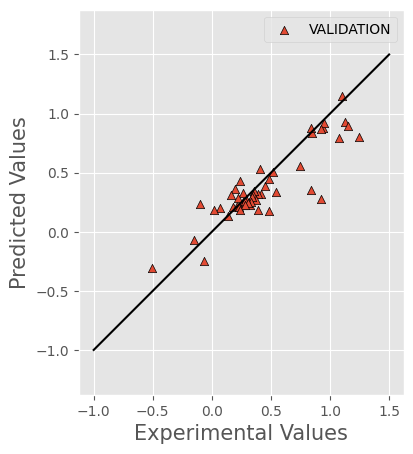

In [28]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

model_ridge = make_pipeline(StandardScaler(), Ridge(alpha=200.0)).fit(train_X, train_y)

out = model_ridge.predict(val_X)

mae = abs(val_y - out).sum() / out.shape[0]
mse = ((val_y - out)**2).sum() / out.shape[0]
r2 = model_ridge.score(val_X, val_y)

print(f"MAE = {mae}, MSE = {mse}, R2 = {r2}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))
plt.scatter(val_y, out, c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
#plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.show()

#### 1.2.2. Calculate performance metrics and generate graphs

TRAIN: MAE = 0.06118034046982321, MSE = 0.00784760946945521, R2 = 0.9414927289633747
VALIDATION: MAE = 0.12317725660143283, MSE = 0.03232361002129537, R2 = 0.758641608962366
TEST: MAE = 0.11481700970869546, MSE = 0.022123034295754566, R2 = 0.8265867819909845
ALL: MAE = 0.07280214719109511, MSE = 0.011735252274990757, R2 = 0.9126870166851876


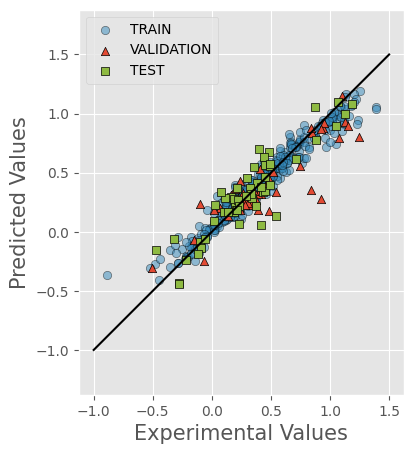

In [29]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_ridge = make_pipeline(StandardScaler(), Ridge(alpha=200.0)).fit(train_X, train_y)

out = [model_ridge.predict(x) for x in datasets_X]

mae = [abs(y - out[i]).sum() / out[i].shape[0] for i, y in enumerate(datasets_y)]
mse = [((y - out[i])**2).sum() / out[i].shape[0] for i, y in enumerate(datasets_y)]
r2 = [model_ridge.score(x, y) for x, y in zip(datasets_X, datasets_y)]

actual_all = Y
out_all = model_ridge.predict(X)

mae_all = abs(actual_all - out_all).sum() / actual_all.shape[0]
mse_all = ((actual_all - out_all)**2).sum() / actual_all.shape[0]
r2_all = model_ridge.score(X, Y)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))

plt.scatter(datasets_y[0], out[0], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(datasets_y[1], out[1], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(datasets_y[2], out[2], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
#plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/IS_predictions_all_Ridge.svg', bbox_inches='tight')
plt.show()

### 1.3. Support Vector Regression

#### 1.3.1. Model training and validation performance metrics calculation

MAE = 0.11763395962471415, MSE = 0.030086816204975424, R2 = 0.7753436096434234


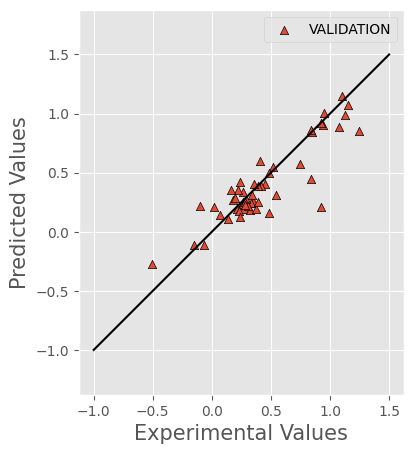

In [30]:
from sklearn.svm import NuSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_svr = make_pipeline(StandardScaler(), NuSVR(nu=0.07, C=64, gamma=0.00009)).fit(train_X, train_y)

out = model_svr.predict(val_X)

mae = abs(val_y - out).sum() / out.shape[0]
mse = ((val_y - out)**2).sum() / out.shape[0]
r2 = model_svr.score(val_X, val_y)

print(f"MAE = {mae}, MSE = {mse}, R2 = {r2}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))
plt.scatter(val_y, out, c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
#plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.show()

#### 1.3.2. Calculate performance metrics and generate graphs

TRAIN: MAE = 0.05333314844894184, MSE = 0.0033205919285997035, R2 = 0.9752435728708477
VALIDATION: MAE = 0.11763395962471415, MSE = 0.030086816204975424, R2 = 0.7753436096434234
TEST: MAE = 0.130249338563593, MSE = 0.029040480370027825, R2 = 0.7723638138344979
ALL: MAE = 0.06754809147042973, MSE = 0.008598365395586732, R2 = 0.9360261784981425


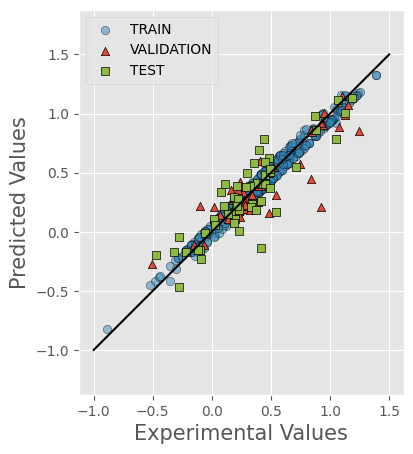

In [32]:
from sklearn.svm import NuSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_svr = make_pipeline(StandardScaler(), NuSVR(nu=0.07, C=64, gamma=0.00009)).fit(train_X, train_y)

out = [model_svr.predict(x) for x in datasets_X]

mae = [abs(y - out[i]).sum() / out[i].shape[0] for i, y in enumerate(datasets_y)]
mse = [((y - out[i])**2).sum() / out[i].shape[0] for i, y in enumerate(datasets_y)]
r2 = [model_svr.score(x, y) for x, y in zip(datasets_X, datasets_y)]

actual_all = Y
out_all = model_svr.predict(X)

mae_all = abs(actual_all - out_all).sum() / actual_all.shape[0]
mse_all = ((actual_all - out_all)**2).sum() / actual_all.shape[0]
r2_all = model_svr.score(X, Y)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))

plt.scatter(datasets_y[0], out[0], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(datasets_y[1], out[1], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(datasets_y[2], out[2], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
#plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/IS_predictions_all_SVR.svg', bbox_inches='tight')
plt.show()

## 2. Chemprop MPNN
### 2.1. Load Data

In [4]:
from rdkit.Chem import Descriptors3D

import pandas as pd
import numpy as np
from pathlib import Path

from lightning import pytorch as pl

from chemprop import data, featurizers, models, nn

num_workers = 10 # number of workers for dataloader. 0 means using main process for data loading
target_columns = ['IS', 'QS'] # classification of activity (either 0 or 1)
feature_columns = ['CHARGE', 'SPIN', 'FE SPIN', 'TEMP'] # name of feature columns in csv

ys = smiles_csv.loc[:, target_columns].values
x_ds = smiles_csv.loc[:, feature_columns].values
x_dsize = 0

datapoint_list = []
for mol, file, y, x_d in zip(mol_list, file_list, ys, x_ds):
    desc_path = osp.join(data_folder, file[:-4], 'tblite-data.npz')
    post_processing = np.load(desc_path)

    charges = post_processing['tblite0_q_A_alpha'] + post_processing['tblite0_q_A_beta']

    d_density_alpha = post_processing['tblite0_p_d_alpha']
    p_density_alpha = post_processing['tblite0_p_p_alpha']
    s_density_alpha = post_processing['tblite0_p_s_alpha']

    d_density_beta = post_processing['tblite0_p_d_beta']
    p_density_beta = post_processing['tblite0_p_p_beta']
    s_density_beta = post_processing['tblite0_p_s_beta']

    chem_pot_alpha = post_processing['tblite0_chem_pot_alpha']
    chem_pot_beta = post_processing['tblite0_chem_pot_beta']
    
    gap_alpha = post_processing['tblite0_gap_alpha']
    gap_beta = post_processing['tblite0_gap_beta']

    hoao_a = post_processing['tblite0_HOAO_alpha']
    hoao_b = post_processing['tblite0_HOAO_beta']

    luao_a = post_processing['tblite0_LUAO_alpha']
    luao_b = post_processing['tblite0_LUAO_beta']

    V_f_final = np.column_stack((charges,
                                 d_density_alpha, p_density_alpha, s_density_alpha, 
                                 d_density_beta, p_density_beta, s_density_beta,
                                 chem_pot_alpha, chem_pot_beta, 
                                 gap_alpha, gap_beta,
                                 hoao_a, hoao_b, luao_a, luao_b))
    
    charge_one_hot = list(np.eye(8)[int(x_d[0] + 4)])
    spin_one_hot = list(np.eye(6)[int(x_d[1] * 2)])
    fe_spin_one_hot = list(np.eye(6)[int(x_d[2] * 2)])

    iron_index = 0
    for i, a in enumerate(mol.GetAtoms()):
        if a.GetAtomicNum() == 26:
            iron_index = i
            break
            
    quadrupole = [post_processing[f'tblite0_qm_A_{x+13*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_qm_A_{x+13*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_ext_qm_e_{x+9*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_ext_qm_e_{x+9*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_ext_qm_Z_{x+9*' '}_alpha'][iron_index] + 
                  post_processing[f'tblite0_ext_qm_Z_{x+9*' '}_beta'][iron_index] 
                  for x in ['zz','yy','xx','xy','xz','yz']] + \
                 [post_processing[f'tblite0_qm_A_alpha'][iron_index], 
                  post_processing[f'tblite0_qm_A_beta'][iron_index],
                  post_processing[f'tblite0_ext_qm_e_alpha'][iron_index],
                  post_processing[f'tblite0_ext_qm_e_beta'][iron_index],
                  post_processing[f'tblite0_ext_qm_Z_alpha'][iron_index],
                  post_processing[f'tblite0_ext_qm_Z_beta'][iron_index]]

    threed_list = list(Descriptors3D.CalcMolDescriptors3D(mol).values())
    
    x_d_final = np.asarray(charge_one_hot + spin_one_hot + fe_spin_one_hot + threed_list + quadrupole + [x_d[3], charges[iron_index]])
    
    x_dsize = x_d_final.shape[0]
    datapoint_list.append(data.MoleculeDatapoint(mol, y, x_d=x_d_final, V_f=V_f_final, name=file))

all_data = np.asarray(datapoint_list)

### 2.2. Split data and train model

In [73]:
import torch
torch.set_float32_matmul_precision('high')
from lightning.pytorch.callbacks.early_stopping import EarlyStopping

from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

from chemprop.nn.transforms import ScaleTransform, GraphTransform, UnscaleTransform

from featurizers.atom import TMCAtomFeaturizer
from featurizers.bond import TMCBondFeaturizer

from sklearn.model_selection import train_test_split

train_data, val_test_data = train_test_split(all_data, test_size=0.2, random_state=42)
val_data, test_data = train_test_split(val_test_data, test_size=0.5, random_state=42)


featurizer = featurizers.SimpleMoleculeMolGraphFeaturizer(
                                atom_featurizer=TMCAtomFeaturizer.complex(),
                                bond_featurizer=TMCBondFeaturizer(),
                                extra_atom_fdim=V_f_final.shape[1])

train_dset = data.MoleculeDataset(train_data, featurizer)
targets_scaler = train_dset.normalize_targets()
X_d_scaler = train_dset.normalize_inputs("X_d")
V_f_scaler = train_dset.normalize_inputs("V_f")

val_dset = data.MoleculeDataset(val_data, featurizer)
val_dset.normalize_targets(targets_scaler)
val_dset.normalize_inputs("X_d", X_d_scaler)
val_dset.normalize_inputs("V_f", V_f_scaler)

test_dset = data.MoleculeDataset(test_data, featurizer)
test_dset.cache = True

train_loader = data.build_dataloader(train_dset, num_workers=num_workers, batch_size=100)
val_loader = data.build_dataloader(val_dset, num_workers=num_workers, shuffle=False)
test_loader = data.build_dataloader(test_dset, num_workers=num_workers, shuffle=False)

n_V_features = featurizer.atom_fdim - featurizer.extra_atom_fdim
V_f_transform = ScaleTransform.from_standard_scaler(V_f_scaler, pad=n_V_features)
graph_transform = GraphTransform(V_f_transform, ScaleTransform([0],[1]))

X_d_transform = ScaleTransform.from_standard_scaler(X_d_scaler)

output_transform = UnscaleTransform.from_standard_scaler(targets_scaler)

mp = nn.BondMessagePassing(d_h=800, depth=4,
                           d_v=featurizer.atom_fdim, 
                           d_e=featurizer.bond_fdim, 
                           graph_transform=graph_transform,
                           dropout=0.2,
                          )
agg = nn.AttentiveAggregation(output_size=800)
ffn = nn.RegressionFFN(
    input_dim=mp.output_dim + x_dsize,
    n_tasks=len(target_columns),
    output_transform=output_transform,
    hidden_dim=400,
    n_layers=3,
    dropout=0.2,
)

batch_norm = True
metric_list = [nn.metrics.MAE(), nn.metrics.MSE(), nn.metrics.R2Score()]
mpnn = models.MPNN(mp, agg, ffn, batch_norm, metric_list, X_d_transform=X_d_transform, init_lr=0.0002)
early_stop_callback = EarlyStopping(monitor="val_loss", 
                                    min_delta=0.00, 
                                    patience=400, 
                                    verbose=False, 
                                    mode="min",
                                    stopping_threshold=0.22)

trainer = pl.Trainer(
    logger=True,
    enable_checkpointing=True,
    enable_progress_bar=True,
    accelerator="gpu",
    devices=1,
    precision="32-true",
    max_epochs=100,
)

trainer.fit(mpnn, train_loader, val_loader)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/iskoulid/.local/miniforge3/envs/dig/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:658: Checkpoint directory /mmfs1/home/iskoulid/ML-MossbauerParameterPrediction/Calculations/lightning_logs/version_615018/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loading `train_dataloader` to estimate number of stepping batches.
/home/iskoulid/.local/miniforge3/envs/dig/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:310: The number of training batches (5) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the train

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


### 2.3. Calculate performance metrics and generate prediction graphs

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Predicting: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Predicting: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Predicting: |          | 0/? [00:00<?, ?it/s]

TRAIN: MAE = 0.03162872117846418, MSE = 0.0017284387838222305, R2 = 0.9871137526925989
VALIDATION: MAE = 0.06627199764893604, MSE = 0.00875715561020339, R2 = 0.9346108622535542
TEST: MAE = 0.06647898680758926, MSE = 0.009875553343593984, R2 = 0.9225896655025768
ALL: MAE = 0.03861821247120013, MSE = 0.0032558149268102064, R2 = 0.975775986087106


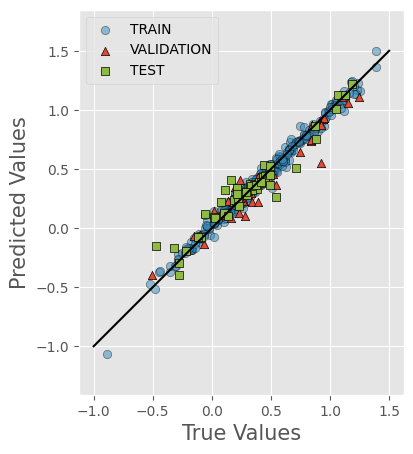

TRAIN: MAE = 0.13861262636664962, MSE = 0.03752591333529731, R2 = 0.9726154651007393
VALIDATION: MAE = 0.46237285078488866, MSE = 0.5359545295097654, R2 = 0.6196550029886816
TEST: MAE = 0.4485608619743924, MSE = 0.38683897091271585, R2 = 0.731487543136542
ALL: MAE = 0.202334442759291, MSE = 0.12264445757413933, R2 = 0.9113251949602151


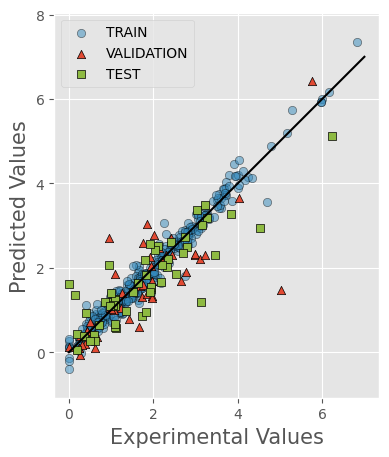

In [24]:
from scripts.utils import load_and_create_dataset_MPNN

from chemprop import data, featurizers, models
from featurizers.atom import TMCAtomFeaturizer
from featurizers.bond import TMCBondFeaturizer

import torch

from lightning import pytorch as pl

from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from datetime import datetime

import json

loaded_data, V_f_final_size = load_and_create_dataset_MPNN('dataset/mossbauer/raw', ['IS', 'QS'], ['CHARGE', 'SPIN', 'FE SPIN', 'TEMP'])

featurizer = featurizers.SimpleMoleculeMolGraphFeaturizer(
                                atom_featurizer=TMCAtomFeaturizer.complex(),
                                bond_featurizer=TMCBondFeaturizer(),
                                extra_atom_fdim=V_f_final_size)

with open('split.json', 'r') as file:
    split = json.load(file)

new_train_data = loaded_data[split['train']]
new_val_data = loaded_data[split['validation']]
new_test_data = loaded_data[split['test']]

new_train_dset = data.MoleculeDataset(new_train_data, featurizer)
new_train_dset.cache = True

new_val_dset = data.MoleculeDataset(new_val_data, featurizer)
new_val_dset.cache = True

new_test_dset = data.MoleculeDataset(new_test_data, featurizer)
new_test_dset.cache = True

new_train_loader = data.build_dataloader(new_train_dset, num_workers=15, shuffle=False)
new_val_loader = data.build_dataloader(new_val_dset, num_workers=15, shuffle=False)
new_test_loader = data.build_dataloader(new_test_dset, num_workers=15, shuffle=False)

model = models.MPNN.load_from_checkpoint('predictor/featurizers/best.ckpt')

trainer = pl.Trainer(
    logger=True,
    enable_checkpointing=True,
    enable_progress_bar=True,
    accelerator="gpu",
    devices=1,
    max_epochs=1,
)

out = [trainer.predict(model, x, return_predictions=True) for x in [new_train_loader, new_val_loader, new_test_loader]]

out_is = [torch.tensor([y for x in o for y in x[:, 0]]).cpu().detach().numpy() for o in out]
actual_is = [torch.tensor([d.y[0] for d in data]).cpu().detach().numpy() for data in [new_train_data, new_val_data, new_test_data]]

mol_name_test = [d.name for d in new_test_data]
mol_name_validation = [d.name for d in new_val_data]
mol_name_train = [d.name for d in new_train_data]
mol_name_all = mol_name_train + mol_name_validation + mol_name_test

mae = [abs(a_is - o_is).sum() / a_is.shape[0] for a_is, o_is in zip(actual_is, out_is)]
mse = [((a_is - o_is)**2).sum() / a_is.shape[0] for a_is, o_is in zip(actual_is, out_is)]
r2 = [r2_score(a_is, o_is) for a_is, o_is in zip(actual_is, out_is)]

actual_is_all = np.concatenate((actual_is[0], actual_is[1], actual_is[2]), axis=0)
out_is_all = np.concatenate((out_is[0], out_is[1], out_is[2]), axis=0)

mae_all = abs(actual_is_all - out_is_all).sum() / actual_is_all.shape[0]
mse_all = ((actual_is_all - out_is_all)**2).sum() / actual_is_all.shape[0]
r2_all = r2_score(actual_is_all, out_is_all)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.style.use('ggplot')

plt.figure(figsize=(5,5))
plt.scatter(actual_is[0], out_is[0], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(actual_is[1], out_is[1], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(actual_is[2], out_is[2], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
plt.xlabel('True Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/IS_predictions_all_MPNN.svg', bbox_inches='tight')
plt.show()

out_qs = [torch.tensor([y for x in o for y in x[:, 1]]).cpu().detach().numpy() for o in out]
actual_qs = [torch.tensor([d.y[1] for d in data]).cpu().detach().numpy() for data in [new_train_data, new_val_data, new_test_data]]

mae = [abs(a_qs - o_qs).sum() / a_qs.shape[0] for a_qs, o_qs in zip(actual_qs, out_qs)]
mse = [((a_qs - o_qs)**2).sum() / a_qs.shape[0] for a_qs, o_qs in zip(actual_qs, out_qs)]
r2 = [r2_score(a_qs, o_qs) for a_qs, o_qs in zip(actual_qs, out_qs)]

actual_qs_all = np.concatenate((actual_qs[0], actual_qs[1], actual_qs[2]), axis=0)
out_qs_all = np.concatenate((out_qs[0], out_qs[1], out_qs[2]), axis=0)

mae_all = abs(actual_qs_all - out_qs_all).sum() / actual_qs_all.shape[0]
mse_all = ((actual_qs_all - out_qs_all)**2).sum() / actual_qs_all.shape[0]
r2_all = r2_score(actual_qs_all, out_qs_all)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.figure(figsize=(5,5))
plt.scatter(actual_qs[0], out_qs[0], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(actual_qs[1], out_qs[1], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(actual_qs[2], out_qs[2], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/QS_predictions_all_MPNN.svg', bbox_inches='tight')
plt.show()

### 2.4. Calculate performance metrics and generate prediction graph with outliers removed

3σ = 1.2925513978784577
i	Mol file	Expt. IS	ML IS	Expt. - ML IS	Expt. QS	ML QS	Expt. - ML QS
23	153.mol		0.208		0.225	0.017		3.127		1.200	1.927
24	158.mol		0.11		0.320	0.210		4.52		2.954	1.566
41	396.mol		0.542		0.262	0.280		0.0		1.617	1.617
MAE = 0.3732772924709321, MSE = 0.23445042278489114, R2 = 0.8165430799231852


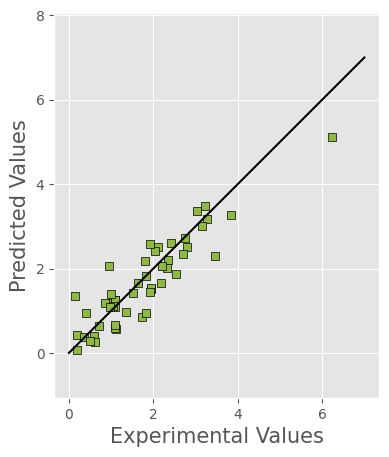

In [25]:
diff_is = abs(actual_is[2] - out_is[2])
diff_qs = abs(actual_qs[2] - out_qs[2])
std_qs = diff_qs.std()
print(f"3σ = {std_qs*3}")
print(f"i\tMol file\tExpt. IS\tML IS\tExpt. - ML IS\tExpt. QS\tML QS\tExpt. - ML QS")
outliers = []
for i, mol in enumerate(new_test_data):
    if diff_qs[i] > std_qs*3: 
        print(f"{i}\t{mol_name_test[i]}\t\t{actual_is[2][i]}\t\t{out_is[2][i]:.3f}\t{diff_is[i]:.3f}\t\t{actual_qs[2][i]}\t\t{out_qs[2][i]:.3f}\t{diff_qs[i]:.3f}")
        outliers.append(i)

actual_qs_no_outliers = np.delete(actual_qs[2], outliers)
out_qs_no_outliers = np.delete(out_qs[2], outliers)

mae = abs(actual_qs_no_outliers - out_qs_no_outliers).sum() / actual_qs_no_outliers.shape[0]
mse = ((actual_qs_no_outliers - out_qs_no_outliers)**2).sum() / actual_qs_no_outliers.shape[0]
r2 = r2_score(actual_qs_no_outliers, out_qs_no_outliers)

print(f"MAE = {mae}, MSE = {mse}, R2 = {r2}")

plt.style.use('ggplot')

plt.figure(figsize=(5,5))
plt.scatter(actual_qs_no_outliers, out_qs_no_outliers, c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
#plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/QS_predictions_MPNN_no_outliers.svg', bbox_inches='tight')
plt.show()

3σ = 0.8575238058659589
i	Mol file	Expt. IS	ML IS	Expt. - ML IS	Expt. QS	ML QS	Expt. - ML QS
237	300.mol		1.09		1.015	0.075		2.76		1.816	0.944
256	322.mol		0.78		0.852	0.072		4.69		3.570	1.120
423	72.mol		-0.068		-0.136	0.068		2.66		1.684	0.976
437	218.mol		0.26		0.225	0.035		0.94		2.705	1.765
442	281.mol		0.84		0.734	0.106		2.78		1.889	0.891
455	427.mol		0.24		0.409	0.169		1.67		0.603	1.067
457	437.mol		0.22		0.314	0.094		1.85		3.031	1.181
463	486.mol		1.098		1.113	0.015		3.11		2.212	0.898
464	504.mol		1.08		1.126	0.046		3.23		2.298	0.932
468	522.mol		0.16		0.082	0.078		5.02		1.470	3.550
476	34.mol		0.48		0.474	0.006		1.74		0.861	0.879
490	140.mol		-0.28		-0.294	0.014		0.15		1.354	1.204
492	153.mol		0.208		0.225	0.017		3.127		1.200	1.927
493	158.mol		0.11		0.320	0.210		4.52		2.954	1.566
497	228.mol		-0.281		-0.396	0.115		6.23		5.124	1.106
502	287.mol		0.37		0.366	0.004		1.827		0.958	0.869
507	325.mol		0.21		0.342	0.132		3.45		2.293	1.157
508	360.mol		0.87		0.864	0.006		0.95		2.069	1.1

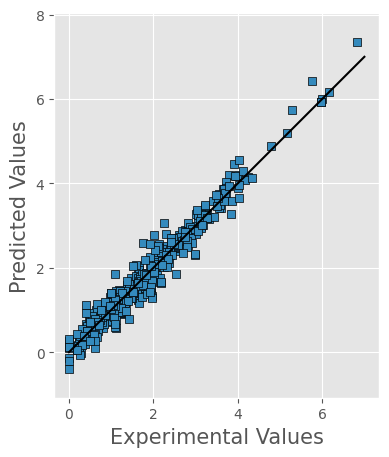

In [26]:
diff_is = abs(actual_is_all - out_is_all)
diff_qs = abs(actual_qs_all - out_qs_all)
std_qs = diff_qs.std()
print(f"3σ = {std_qs*3}")
print(f"i\tMol file\tExpt. IS\tML IS\tExpt. - ML IS\tExpt. QS\tML QS\tExpt. - ML QS")
outliers = []
for i, mol in enumerate(loaded_data):
    if diff_qs[i] > std_qs*3: 
        print(f"{i}\t{mol_name_all[i]}\t\t{actual_is_all[i]}\t\t{out_is_all[i]:.3f}\t{diff_is[i]:.3f}\t\t{actual_qs_all[i]}\t\t{out_qs_all[i]:.3f}\t{diff_qs[i]:.3f}")
        outliers.append(i)

actual_qs_no_outliers = np.delete(actual_qs_all, outliers)
out_qs_no_outliers = np.delete(out_qs_all, outliers)

mae = abs(actual_qs_no_outliers - out_qs_no_outliers).sum() / actual_qs_no_outliers.shape[0]
mse = ((actual_qs_no_outliers - out_qs_no_outliers)**2).sum() / actual_qs_no_outliers.shape[0]
r2 = r2_score(actual_qs_no_outliers, out_qs_no_outliers)

print(f"MAE = {mae}, MSE = {mse}, R2 = {r2}")

plt.style.use('ggplot')

plt.figure(figsize=(5,5))
plt.scatter(actual_qs_no_outliers, out_qs_no_outliers, c='C1', edgecolors='k', marker='s', s=36, label='ALL')

plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
#plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/QS_predictions_MPNN_no_outliers_all.svg', bbox_inches='tight')
plt.show()

## 3. SphereNet

### 3.1. Load dataset

In [ ]:
from featurizers.mossbauer_dataset import Mossbauer

dataset = Mossbauer(root='dataset/')

### 3.2. Split dataset

In [4]:
import torch
import json

dataset._data.y = torch.stack((dataset._data.IS, dataset._data.QS)).T
print(dataset._data)

with open('split.json', 'r') as file:
    split = json.load(file)

train_dataset = dataset[split['train']]
val_dataset = dataset[split['validation']]
test_dataset = dataset[split['test']]

Data(y=[522, 2], pos=[44473, 3], z=[44473], IS=[522], QS=[522], node_feature=[44473, 61])


### 3.3. Create model

In [9]:
from dig.threedgraph.method import SphereNet, run
from dig.threedgraph.evaluation import threedEvaluator

model = SphereNet(energy_and_force=False, cutoff=4.5, num_layers=2,
                  hidden_channels=300, out_channels=2, int_emb_size=300,
                  basis_emb_size_dist=8, basis_emb_size_angle=8, basis_emb_size_torsion=8,
                  out_emb_channels=150, num_spherical=6, num_radial=4, envelope_exponent=5,
                  num_before_skip=1, num_after_skip=2, num_output_layers=3, use_extra_node_feature=True, extra_node_feature_dim=61)

loss_func = torch.nn.L1Loss()
evaluation = threedEvaluator()

### 3.4. Train model

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

run3d = run()
run3d.run(device, train_dataset, val_dataset, test_dataset, model, loss_func, evaluation,
          epochs=600, batch_size=32, vt_batch_size=32, lr=0.0005, lr_decay_factor=0.4, lr_decay_step_size=50)


=====Epoch 1

Training...


100%|██████████| 14/14 [00:01<00:00,  8.59it/s]



Evaluating...



100%|██████████| 2/2 [00:00<00:00, 19.69it/s]



Testing...


...



Evaluating...



100%|██████████| 2/2 [00:00<00:00, 19.44it/s]



Testing...



100%|██████████| 2/2 [00:00<00:00, 19.67it/s]


{'Train': 0.33313423501593725, 'Validation': 0.4752749800682068, 'Test': 0.5655283331871033}
Best validation MAE so far: 0.4498457610607147
Test MAE when got best validation result: 0.625044584274292


In [12]:
torch.save(model.state_dict(), "best_SphereNet_QS_full.pkl")

### 3.5. Calculate performance metrics and generate graphs

/home/iskoulid/.local/miniforge3/envs/dig/lib/python3.12/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  warnings.warn(out)


TRAIN: MAE = 0.15905201863899504, MSE = 0.05674456406554444, R2 = 0.5769451260566711
VALIDATION: MAE = 0.1788325493152325, MSE = 0.05995228657355675, R2 = 0.552340030670166
TEST: MAE = 0.30260366763708724, MSE = 0.4745135397281287, R2 = -2.719513177871704
ALL: MAE = 0.1755976475975066, MSE = 0.09948125378838901, R2 = 0.2598365545272827


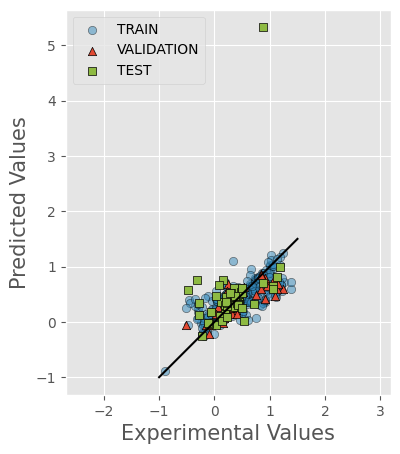

TRAIN: MAE = 0.5459925882536159, MSE = 0.8093198780819095, R2 = 0.4093988537788391
VALIDATION: MAE = 0.7717172916118915, MSE = 1.2891748868502104, R2 = 0.08512532711029053
TEST: MAE = 0.8284529200140035, MSE = 1.358109528163694, R2 = 0.05730968713760376
ALL: MAE = 0.5971575039099917, MSE = 0.9128415630238266, R2 = 0.33999425172805786


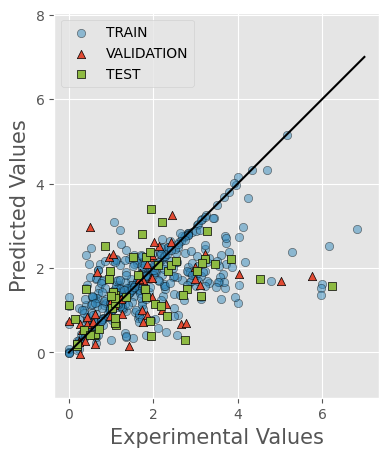

In [13]:
from torch_geometric.data import DataLoader
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import numpy as np

from dig.threedgraph.method import SphereNet, run
from dig.threedgraph.evaluation import threedEvaluator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(torch.load("best_SphereNet_QS_full.pkl", weights_only=True))
model.eval()
model.to(device)

train_loader = DataLoader(train_dataset, 32, shuffle=False)
val_loader = DataLoader(val_dataset, len(val_dataset), shuffle=False)
test_loader = DataLoader(test_dataset, len(test_dataset), shuffle=False)
out = []
actual = []

train_y = []
train_y_hat = []
for batch in train_loader:
    batch.to(device)
    train_y.append(batch.y.cpu().detach().numpy())
    train_y_hat.append(model(batch).cpu().detach().numpy())

out.append(np.concatenate(tuple(train_y_hat), axis=0))
actual.append(np.concatenate(tuple(train_y), axis=0))

for batch in val_loader:
    batch.to(device)
    actual.append(batch.y.cpu().detach().numpy())
    out.append(model(batch).cpu().detach().numpy())
for batch in test_loader:
    batch.to(device)
    actual.append(batch.y.cpu().detach().numpy())
    out.append(model(batch).cpu().detach().numpy())

mae = [abs(a[:, 0] - o[:, 0]).sum()/o.shape[0] for a, o in zip(actual, out)]
mse = [((a[:, 0] - o[:, 0])**2).sum()/o.shape[0] for a, o in zip(actual, out)]
r2 = [r2_score(a[:, 0], o[:, 0]) for a, o in zip(actual, out)]

actual_is_all = np.concatenate((actual[0][:, 0], actual[1][:, 0], actual[2][:, 0]), axis=0)
out_is_all = np.concatenate((out[0][:, 0], out[1][:, 0], out[2][:, 0]), axis=0)

mae_all = abs(actual_is_all - out_is_all).sum() / actual_is_all.shape[0]
mse_all = ((actual_is_all - out_is_all)**2).sum() / actual_is_all.shape[0]
r2_all = r2_score(actual_is_all, out_is_all)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.style.use('ggplot')
plt.figure(figsize=(5,5))

plt.scatter(actual[0][:, 0], out[0][:, 0], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(actual[1][:, 0], out[1][:, 0], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(actual[2][:, 0], out[2][:, 0], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([-1.0, 1.5], [-1.0, 1.5], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/IS_predictions_all_SphereNet_QS_full.svg', bbox_inches='tight')
plt.show()

mae = [abs(a[:, 1] - o[:, 1]).sum()/o.shape[0] for a, o in zip(actual, out)]
mse = [((a[:, 1] - o[:, 1])**2).sum()/o.shape[0] for a, o in zip(actual, out)]
r2 = [r2_score(a[:, 1], o[:, 1]) for a, o in zip(actual, out)]

actual_qs_all = np.concatenate((actual[0][:, 1], actual[1][:, 1], actual[2][:, 1]), axis=0)
out_qs_all = np.concatenate((out[0][:, 1], out[1][:, 1], out[2][:, 1]), axis=0)

mae_all = abs(actual_qs_all - out_qs_all).sum() / actual_qs_all.shape[0]
mse_all = ((actual_qs_all - out_qs_all)**2).sum() / actual_qs_all.shape[0]
r2_all = r2_score(actual_qs_all, out_qs_all)

print(f"TRAIN: MAE = {mae[0]}, MSE = {mse[0]}, R2 = {r2[0]}")
print(f"VALIDATION: MAE = {mae[1]}, MSE = {mse[1]}, R2 = {r2[1]}")
print(f"TEST: MAE = {mae[2]}, MSE = {mse[2]}, R2 = {r2[2]}")
print(f"ALL: MAE = {mae_all}, MSE = {mse_all}, R2 = {r2_all}")

plt.figure(figsize=(5,5))

plt.scatter(actual[0][:, 1], out[0][:, 1], c='C1', edgecolors='k', marker='o', s=36, label='TRAIN', alpha=0.5)
plt.scatter(actual[1][:, 1], out[1][:, 1], c='C0', edgecolors='k', marker='^', s=36, label='VALIDATION')
plt.scatter(actual[2][:, 1], out[2][:, 1], c='C5', edgecolors='k', marker='s', s=36, label='TEST')

plt.plot([0.0, 7.0], [0.0, 7.0], 'k-')
plt.xlabel('Experimental Values', fontsize=15)
plt.ylabel('Predicted Values', fontsize=15)
plt.axis('equal')
plt.legend()
plt.subplots_adjust(left=0.25)
plt.savefig('figures/QS_predictions_all_SphereNet_QS_full.svg', bbox_inches='tight')
plt.show()